# Marketing Growth Analytics

# Problem Statement

Efektivitas iklan Meta Ads yang bergantung pada konten, tingginya sensitivitas harga, serta kualitas produk dan layanan yang kurang optimal. Solusinya meliputi pengoptimalan konten iklan dengan storytelling kreatif, penambahan testimoni untuk memperkuat validasi harga (value for money), serta peningkatan kontrol mutu produk dan layanan yang responsif.

## Import Data

In [2]:
# Import Library
import pandas as pd
import numpy as np
from scipy.stats import zscore
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
## Import Excel
df = pd.read_csv("data_marketing_growth_analytics.csv")

df

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,2025-02-14,Email,facebook,Mobile,6,2,0,0,0,0,0,49,1470,0,0
796,797,2025-01-21,Email,instagram,Mobile,5,10,0,1,1,361793,0,47,564,0,2
797,798,2025-01-11,Email,tiktok,Tablet,3,14,0,1,0,0,0,5,195,0,0
798,799,2025-02-19,Social Media,tiktok,Mobile,5,16,0,0,0,0,0,3,84,0,0


# Data Exploration

## head()

In [3]:
'''
Kode head() ini digunakan untuk Menampilkan 5 baris pertama (default) dan untuk menampilkan Nama kolom apa saja yang ada
'''
# Copy data biar tidak ditiban
df_copy = df.copy()
df_copy.head()

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0


## Info

In [4]:
'''
Kode infp() ini digunakan untuk Menampilkan, Jumlah baris dan kolom, tipe data, dan jumlah missing value
'''
# Info data
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   user_id           800 non-null    int64
 1   first_visit_date  800 non-null    str  
 2   channel           800 non-null    str  
 3   source            800 non-null    str  
 4   device            800 non-null    str  
 5   sessions          800 non-null    int64
 6   page_views        800 non-null    int64
 7   bounce            800 non-null    int64
 8   add_to_cart       800 non-null    int64
 9   purchase          800 non-null    int64
 10  revenue           800 non-null    int64
 11  ad_cost           800 non-null    int64
 12  clicks            800 non-null    int64
 13  impressions       800 non-null    int64
 14  repeat_purchase   800 non-null    int64
 15  retention_month   800 non-null    int64
dtypes: int64(12), str(4)
memory usage: 125.8 KB


Data Marketing Web merupakan data penjualan produk dalam iklan yang memiliki 800 Baris dan 16 Kolom, data Marketing Web ini memiliki 4 string, 12 int. tetapi ada beberapa data kolom yang perluh diubah tipe datanya seperti first_visit_date menjadi tipe DATE.

In [5]:
'''
Kode describe() digunakan untuk Cek struktur dan data sekaligus: melihat jumlah data, jumlah rata rata, nilai max dan min, 
Kuartil 1 sampa 3 (Q1 - Q3), Standar deviasi(std).
'''
# describsi data
df_copy.describe()

,user_id,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,4.131250,10.053750,0.032500,0.411250,0.187500,51254.881250,13686.133750,24.366250,553.375000,0.060000,0.427500
std,231.0844,1.970121,5.482329,0.177435,0.492368,0.390557,121909.726919,23499.467179,14.369071,427.273115,0.237635,1.100572
min,1.0000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,8.000000,0.000000,0.000000
25%,200.7500,3.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,11.000000,208.750000,0.000000,0.000000
50%,400.5000,4.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.000000,442.000000,0.000000,0.000000
75%,600.2500,6.000000,15.000000,0.000000,1.000000,0.000000,0.000000,21996.750000,37.000000,812.000000,0.000000,0.000000
max,800.0000,7.000000,19.000000,1.000000,1.000000,1.000000,495675.000000,79437.000000,49.000000,1911.000000,1.000000,5.000000


# Cleaning Data

## Missing Value

In [6]:
Missing = df_copy.isnull().sum()
print(f"Missing Value:")
print(Missing)

Missing Value:
user_id             0
first_visit_date    0
channel             0
source              0
device              0
sessions            0
page_views          0
bounce              0
add_to_cart         0
purchase            0
revenue             0
ad_cost             0
clicks              0
impressions         0
repeat_purchase     0
retention_month     0
dtype: int64


Mencari missing value pada data Marketing Ad bisa menggunakan Pyton dan hasilnya tidak terdapat missing value di data Superstore yang membuat datanya siap untuk pemeriksaan selanjutnya.

## Duplikasi

In [7]:
'''
Saya menggunakan kode duplicated untuk mencari data yang terdapat duplikate (data yang sama), setelah meancari saya mengubah jumlah
data menjadi persen.
'''
## Duplicated 
SemuaData = df_copy.duplicated().sum()

#Buat jadi %
a = SemuaData / len(df_copy) * 100
print("=" * 50)
print(f"Duplikat: {SemuaData}")
print(f"Duplikat persen: {a:.2f}%")
print("=" * 50)

Duplikat: 0
Duplikat persen: 0.00%


Setelah itu, melanjutkan untuk mencari duplikasi dengan mengguanalan Pyton. Hasilnya tidak terdapat data yang duplikasi di data Marketing Ad yang membuat data tersebut bisa lanjut untuk pengecekan selanjutnya.

In [8]:
df_copy

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,2025-02-14,Email,facebook,Mobile,6,2,0,0,0,0,0,49,1470,0,0
796,797,2025-01-21,Email,instagram,Mobile,5,10,0,1,1,361793,0,47,564,0,2
797,798,2025-01-11,Email,tiktok,Tablet,3,14,0,1,0,0,0,5,195,0,0
798,799,2025-02-19,Social Media,tiktok,Mobile,5,16,0,0,0,0,0,3,84,0,0


### Encoder

In [9]:
'''
Kode le.fit_transform() digunakan untuk mengubah data string menjadi data integer.
'''
le = LabelEncoder()

df_copy["first_visit_date_C"] = le.fit_transform(df["first_visit_date"])
df_copy["channel_C"] = le.fit_transform(df["channel"])
df_copy["source_C"] = le.fit_transform(df["source"])
df_copy["device_C"] = le.fit_transform(df["device"])
df_copy

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month,first_visit_date_C,channel_C,source_C,device_C
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2,47,3,4,1
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0,4,3,2,1
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0,25,3,5,1
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0,54,2,2,1
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0,3,3,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,2025-02-14,Email,facebook,Mobile,6,2,0,0,0,0,0,49,1470,0,0,44,0,2,1
796,797,2025-01-21,Email,instagram,Mobile,5,10,0,1,1,361793,0,47,564,0,2,20,0,4,1
797,798,2025-01-11,Email,tiktok,Tablet,3,14,0,1,0,0,0,5,195,0,0,10,0,5,2
798,799,2025-02-19,Social Media,tiktok,Mobile,5,16,0,0,0,0,0,3,84,0,0,49,4,5,1


## Outlier

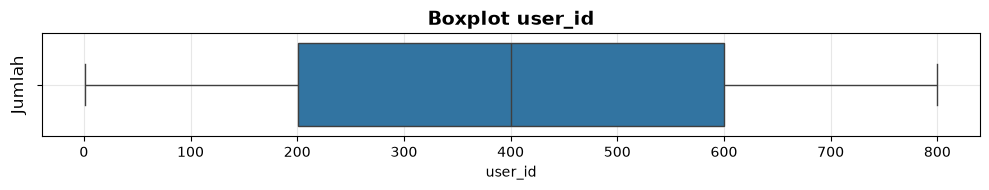

In [10]:
df_box = df_copy.copy()

# Buat boxplot user_id
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["user_id"])
plt.title("Boxplot user_id", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

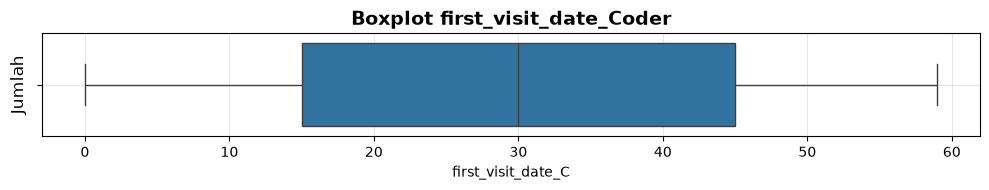

In [11]:
# Buat boxplot first_visit_date_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["first_visit_date_C"])
plt.title("Boxplot first_visit_date_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

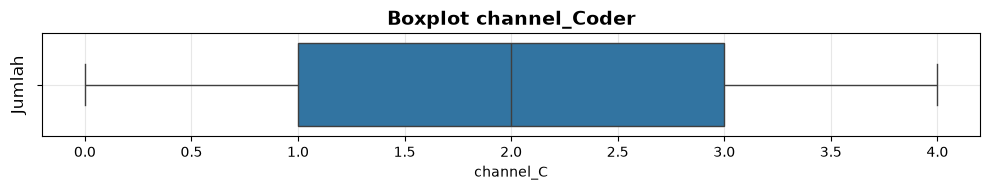

In [12]:
# Buat boxplot channel_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["channel_C"])
plt.title("Boxplot channel_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

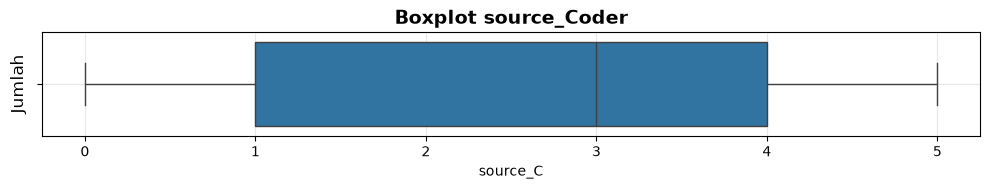

In [13]:
# Buat boxplot source_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["source_C"])
plt.title("Boxplot source_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

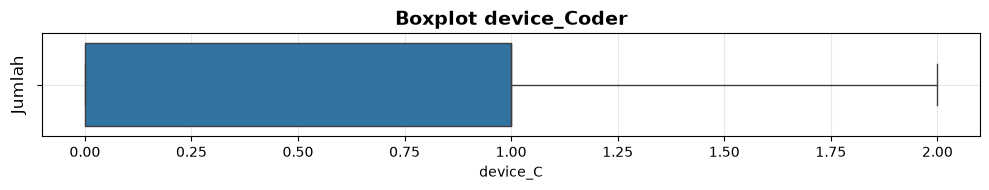

In [14]:
# Buat boxplot device_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["device_C"])
plt.title("Boxplot device_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

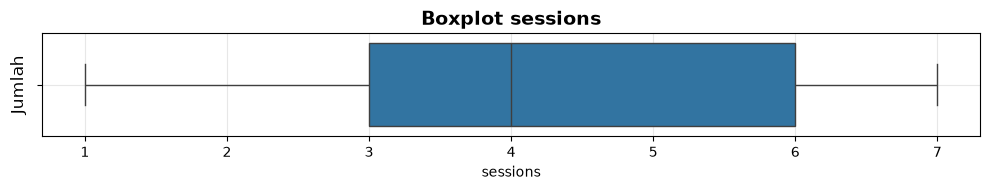

In [15]:
# Buat boxplot sessions
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["sessions"])
plt.title("Boxplot sessions", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

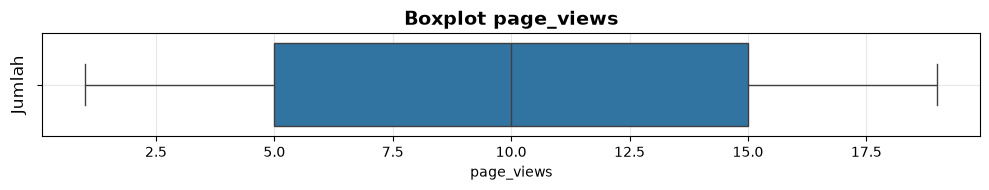

In [16]:
# Buat boxplot page_views
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["page_views"])
plt.title("Boxplot page_views", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

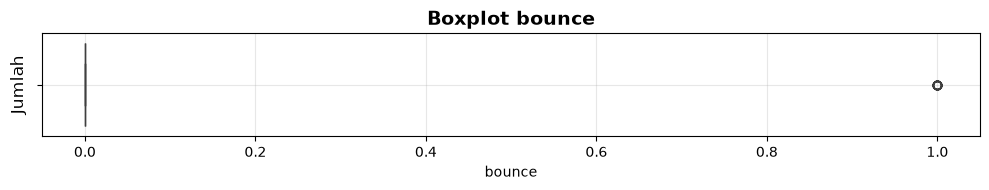

In [17]:
# Buat boxplot bounce
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["bounce"])
plt.title("Boxplot bounce", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

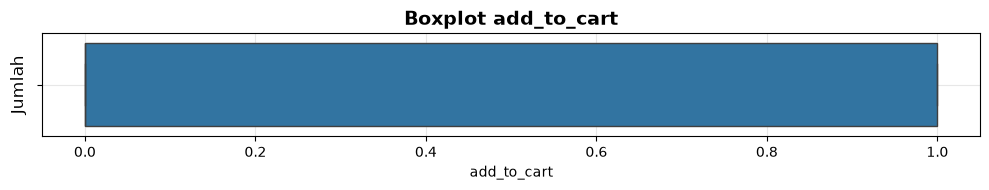

In [18]:
# Buat boxplot add_to_cart
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["add_to_cart"])
plt.title("Boxplot add_to_cart", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

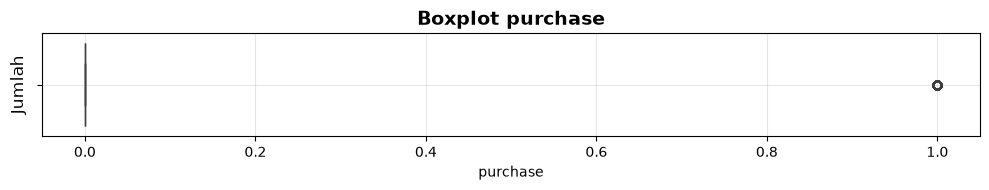

In [19]:
# Buat boxplot purchase
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["purchase"])
plt.title("Boxplot purchase", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

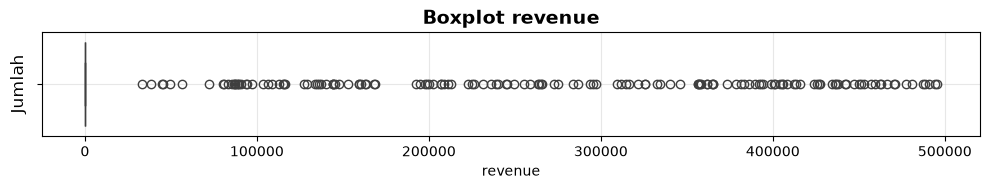

In [20]:
# Buat boxplot revenue
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["revenue"])
plt.title("Boxplot revenue", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

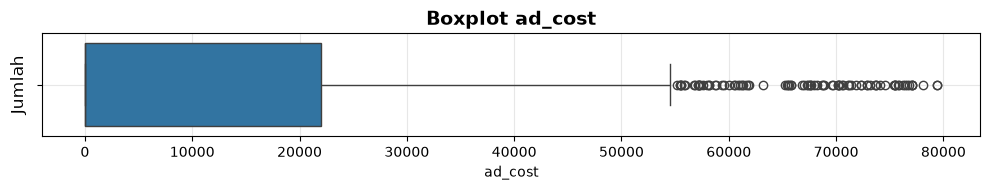

In [21]:
# Buat boxplot ad_cost
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["ad_cost"])
plt.title("Boxplot ad_cost", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

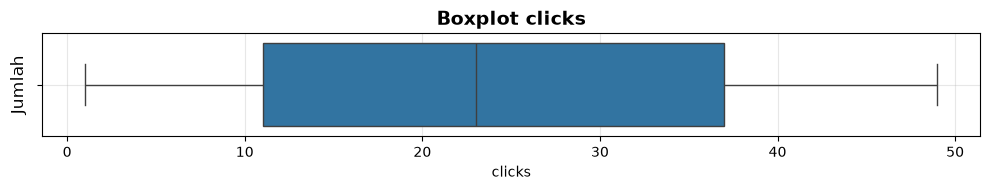

In [22]:
# Buat boxplot clicks
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["clicks"])
plt.title("Boxplot clicks", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

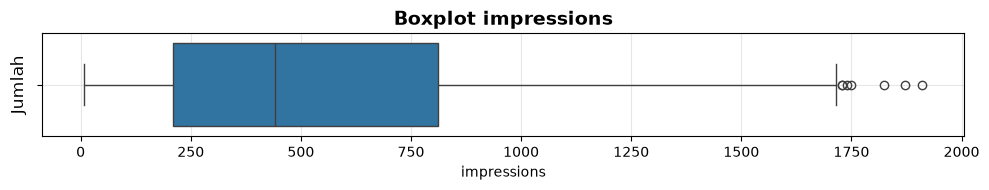

In [23]:
# Buat boxplot impressions
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["impressions"])
plt.title("Boxplot impressions", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

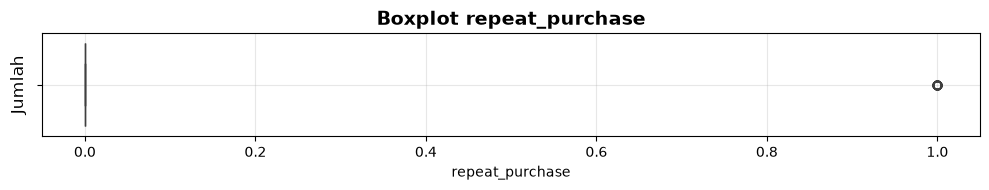

In [24]:
# Buat boxplot repeat_purchase
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["repeat_purchase"])
plt.title("Boxplot repeat_purchase", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

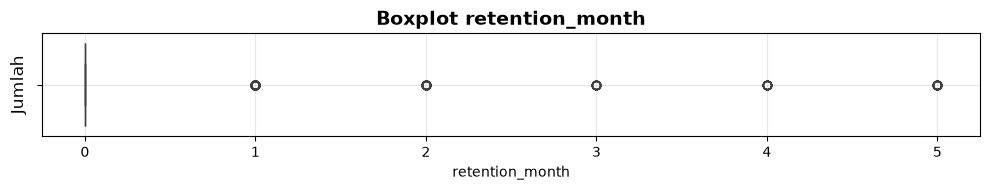

In [25]:
# Buat boxplot retention_month
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["retention_month"])
plt.title("Boxplot retention_month", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

Pada chart boxplot diatas, terdapat beberapa kolom yang memiliki Outlier, seperti kolom: bounce, purchase, revenue, ad_cost, impressions, repeat_purchase, dan retention_month.

### Zscore

#### bounce

In [26]:
'''
Saya menggunakan zscore pada Kolom Sales untuk mencari Outlier dengan mencari dengan membuat kolom baru dan mencari 
nilai yang lebih atau kurang dari 2
'''
dfZ = df_copy
dfZ["z_Score_bounce"] = zscore(dfZ["bounce"])
#Mencari Outlier dengan menghitung nilai absolut yang lebih besar dari 2
Outlier_bounce = dfZ[dfZ["z_Score_bounce"].abs()>2]
Outlier_bounce

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,...,ad_cost,clicks,impressions,repeat_purchase,retention_month,first_visit_date_C,channel_C,source_C,device_C,z_Score_bounce
14,15,2025-02-16,Paid Ads,direct,Desktop,5,1,1,1,0,...,39529,41,1312,0,0,46,2,0,0,5.456119
21,22,2025-02-18,Referral,facebook,Desktop,5,1,1,0,0,...,0,6,126,0,0,48,3,2,0,5.456119
74,75,2025-02-05,Organic Search,instagram,Mobile,3,1,1,1,0,...,0,41,943,0,0,35,1,4,1,5.456119
89,90,2025-01-10,Organic Search,instagram,Mobile,4,1,1,0,0,...,0,23,460,0,0,9,1,4,1,5.456119
106,107,2025-02-13,Organic Search,tiktok,Desktop,6,1,1,1,0,...,0,37,185,0,0,43,1,5,0,5.456119
111,112,2025-02-16,Paid Ads,email,Mobile,5,1,1,1,0,...,71086,35,840,0,0,46,2,1,1,5.456119
164,165,2025-02-12,Email,email,Mobile,4,1,1,0,0,...,0,10,270,0,0,42,0,1,1,5.456119
199,200,2025-02-26,Social Media,instagram,Desktop,6,1,1,0,0,...,0,46,1150,0,0,56,4,4,0,5.456119
214,215,2025-02-13,Paid Ads,direct,Mobile,2,1,1,0,0,...,65839,5,30,0,0,43,2,0,1,5.456119
257,258,2025-01-20,Organic Search,instagram,Desktop,3,1,1,0,0,...,0,41,656,0,0,19,1,4,0,5.456119


In [27]:
'''
Setelah mencari Outleir, saya menghitung Total Outleir yang ditemukan dan menghitung Outleir Quantity per Category
'''
Zbounce = (dfZ["z_Score_bounce"].abs()>2).sum()
#Buat jadi %
a = Zbounce / len(df_copy) * 100
print(f"Outlier bounce: {Zbounce}")
print(f"Outlier bounce persen: {a:.2f}%")
#Menghitung Outlier per Category
print("=" * 50)
Outlier_bounce_per_source = dfZ[dfZ["z_Score_bounce"].abs() > 2].groupby("source")["z_Score_bounce"].count()
print("Jumlah Outlier bounce per source:")
print(Outlier_bounce_per_source)
print("=" * 50)

Outlier bounce: 26
Outlier bounce persen: 3.25%
Jumlah Outlier bounce per source:
source
direct       5
email        5
facebook     3
google       1
instagram    8
tiktok       4
Name: z_Score_bounce, dtype: int64


#### purchase

In [28]:
'''
Saya menggunakan zscore pada Kolom Sales untuk mencari Outlier dengan mencari dengan membuat kolom baru dan mencari 
nilai yang lebih atau kurang dari 2
'''
dfZ = df_copy
dfZ["z_Score_purchase"] = zscore(dfZ["purchase"])
#Mencari Outlier dengan menghitung nilai absolut yang lebih besar dari 2
Outlier_purchase = dfZ[dfZ["z_Score_purchase"].abs()>2]
Outlier_purchase

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,...,clicks,impressions,repeat_purchase,retention_month,first_visit_date_C,channel_C,source_C,device_C,z_Score_bounce,z_Score_purchase
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,...,40,880,0,2,47,3,4,1,-0.183280,2.081666
5,6,2025-01-20,Paid Ads,instagram,Mobile,3,7,0,1,1,...,35,490,0,2,19,2,4,1,-0.183280,2.081666
6,7,2025-01-24,Organic Search,tiktok,Mobile,4,10,0,1,1,...,6,84,0,4,23,1,5,1,-0.183280,2.081666
7,8,2025-02-09,Organic Search,direct,Mobile,3,17,0,1,1,...,44,572,0,2,39,1,0,1,-0.183280,2.081666
11,12,2025-01-24,Organic Search,google,Mobile,6,12,0,1,1,...,31,527,0,4,23,1,3,1,-0.183280,2.081666
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
771,772,2025-01-02,Organic Search,google,Mobile,7,8,0,1,1,...,45,765,0,3,1,1,3,1,-0.183280,2.081666
774,775,2025-01-07,Social Media,email,Mobile,7,1,1,1,1,...,30,600,0,2,6,4,1,1,5.456119,2.081666
785,786,2025-02-16,Organic Search,email,Mobile,5,4,0,1,1,...,19,247,0,1,46,1,1,1,-0.183280,2.081666
790,791,2025-01-27,Social Media,google,Mobile,6,7,0,1,1,...,3,48,1,1,26,4,3,1,-0.183280,2.081666


In [29]:
'''
Setelah mencari Outleir, saya menghitung Total Outleir yang ditemukan dan menghitung Outleir Quantity per Category
'''
Zpurchase = (dfZ["z_Score_purchase"].abs()>2).sum()
#Buat jadi %
a = Zpurchase / len(df_copy) * 100
print(f"Outlier purchase: {Zpurchase}")
print(f"Outlier purchase persen: {a:.2f}%")
#Menghitung Outlier per Category
print("=" * 50)
Outlier_purchase_per_source = dfZ[dfZ["z_Score_purchase"].abs() > 2].groupby("source")["z_Score_purchase"].count()
print("Jumlah Outlier purchase per source:")
print(Outlier_purchase_per_source)
print("=" * 50)

Outlier purchase: 150
Outlier purchase persen: 18.75%
Jumlah Outlier purchase per source:
source
direct       24
email        30
facebook     21
google       26
instagram    22
tiktok       27
Name: z_Score_purchase, dtype: int64


#### revenue

In [30]:
'''
Saya menggunakan zscore pada Kolom Sales untuk mencari Outlier dengan mencari dengan membuat kolom baru dan mencari 
nilai yang lebih atau kurang dari 2
'''
dfZ = df_copy
dfZ["z_Score_revenue"] = zscore(dfZ["revenue"])
#Mencari Outlier dengan menghitung nilai absolut yang lebih besar dari 2
Outlier_revenue = dfZ[dfZ["z_Score_revenue"].abs()>2]
Outlier_revenue

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,...,impressions,repeat_purchase,retention_month,first_visit_date_C,channel_C,source_C,device_C,z_Score_bounce,z_Score_purchase,z_Score_revenue
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,...,880,0,2,47,3,4,1,-0.183280,2.081666,2.873291
5,6,2025-01-20,Paid Ads,instagram,Mobile,3,7,0,1,1,...,490,0,2,19,2,4,1,-0.183280,2.081666,3.171567
25,26,2025-01-12,Organic Search,facebook,Mobile,1,11,0,1,1,...,782,1,2,11,1,2,1,-0.183280,2.081666,3.331227
47,48,2025-01-24,Paid Ads,email,Mobile,3,14,0,1,1,...,37,0,1,23,2,1,1,-0.183280,2.081666,3.635438
67,68,2025-01-08,Social Media,google,Mobile,4,16,0,1,1,...,962,0,1,7,4,3,1,-0.183280,2.081666,2.019035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,756,2025-02-12,Email,direct,Desktop,4,4,0,1,1,...,440,0,4,42,0,0,0,-0.183280,2.081666,2.813398
759,760,2025-02-23,Referral,email,Desktop,7,5,0,1,1,...,1584,0,5,53,3,1,0,-0.183280,2.081666,2.419147
771,772,2025-01-02,Organic Search,google,Mobile,7,8,0,1,1,...,765,0,3,1,1,3,1,-0.183280,2.081666,3.273690
774,775,2025-01-07,Social Media,email,Mobile,7,1,1,1,1,...,600,0,2,6,4,1,1,5.456119,2.081666,3.161291


In [31]:
'''
Setelah mencari Outleir, saya menghitung Total Outleir yang ditemukan dan menghitung Outleir Quantity per Category
'''
Zrevenue = (dfZ["z_Score_revenue"].abs()>2).sum()
#Buat jadi %
a = Zrevenue / len(df_copy) * 100
print(f"Outlier revenue: {Zrevenue}")
print(f"Outlier revenue persen: {a:.2f}%")
#Menghitung Outlier per Category
print("=" * 50)
Outlier_revenue_per_source = dfZ[dfZ["z_Score_revenue"].abs() > 2].groupby("source")["z_Score_revenue"].count()
print("Jumlah Outlier revenue per source:")
print(Outlier_revenue_per_source)
print("=" * 50)

Outlier revenue: 70
Outlier revenue persen: 8.75%
Jumlah Outlier revenue per source:
source
direct       13
email        14
facebook      9
google       15
instagram    10
tiktok        9
Name: z_Score_revenue, dtype: int64


#### ad_cost

In [32]:
'''
Saya menggunakan zscore pada Kolom Sales untuk mencari Outlier dengan mencari dengan membuat kolom baru dan mencari 
nilai yang lebih atau kurang dari 2
'''
dfZ = df_copy
dfZ["z_Score_ad_cost"] = zscore(dfZ["ad_cost"])
#Mencari Outlier dengan menghitung nilai absolut yang lebih besar dari 2
Outlier_ad_cost = dfZ[dfZ["z_Score_ad_cost"].abs()>2]
Outlier_ad_cost

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,...,repeat_purchase,retention_month,first_visit_date_C,channel_C,source_C,device_C,z_Score_bounce,z_Score_purchase,z_Score_revenue,z_Score_ad_cost
30,31,2025-02-14,Paid Ads,direct,Mobile,3,1,0,1,0,...,0,0,44,2,0,1,-0.183280,-0.480384,-0.420696,2.799723
59,60,2025-02-14,Paid Ads,email,Mobile,4,14,0,0,0,...,0,0,44,2,1,1,-0.183280,-0.480384,-0.420696,2.404062
111,112,2025-02-16,Paid Ads,email,Mobile,5,1,1,1,0,...,0,0,46,2,1,1,5.456119,-0.480384,-0.420696,2.444131
121,122,2025-01-09,Paid Ads,email,Desktop,3,5,0,0,0,...,0,0,8,2,1,0,-0.183280,-0.480384,-0.420696,2.404148
126,127,2025-02-17,Paid Ads,facebook,Desktop,2,6,0,0,0,...,0,0,47,2,2,0,-0.183280,-0.480384,-0.420696,2.342363
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
724,725,2025-02-15,Paid Ads,tiktok,Mobile,6,3,0,0,0,...,0,0,45,2,5,1,-0.183280,-0.480384,-0.420696,2.047448
727,728,2025-02-27,Paid Ads,direct,Mobile,5,19,0,1,0,...,0,0,57,2,0,1,-0.183280,-0.480384,-0.420696,2.381026
741,742,2025-01-05,Paid Ads,email,Mobile,5,16,0,0,0,...,0,0,4,2,1,1,-0.183280,-0.480384,-0.420696,2.107232
744,745,2025-01-12,Paid Ads,instagram,Mobile,4,9,0,1,1,...,0,1,11,2,4,1,-0.183280,2.081666,1.757490,2.347643


In [33]:
'''
Setelah mencari Outleir, saya menghitung Total Outleir yang ditemukan dan menghitung Outleir Quantity per Category
'''
Zad_cost = (dfZ["z_Score_ad_cost"].abs()>2).sum()
#Buat jadi %
a = Zad_cost / len(df_copy) * 100
print(f"Outlier ad_cost: {Zad_cost}")
print(f"Outlier ad_cost persen: {a:.2f}%")
#Menghitung Outlier per Category
print("=" * 50)
Outlier_ad_cost_per_source = dfZ[dfZ["z_Score_ad_cost"].abs() > 2].groupby("source")["z_Score_ad_cost"].count()
print("Jumlah Outlier ad_cost per source:")
print(Outlier_ad_cost_per_source)
print("=" * 50)

Outlier ad_cost: 64
Outlier ad_cost persen: 8.00%
Jumlah Outlier ad_cost per source:
source
direct       11
email         9
facebook      9
google       11
instagram    15
tiktok        9
Name: z_Score_ad_cost, dtype: int64


#### impressions

In [34]:
'''
Saya menggunakan zscore pada Kolom Sales untuk mencari Outlier dengan mencari dengan membuat kolom baru dan mencari 
nilai yang lebih atau kurang dari 2
'''
dfZ = df_copy
dfZ["z_Score_impressions"] = zscore(dfZ["impressions"])
#Mencari Outlier dengan menghitung nilai absolut yang lebih besar dari 2
Outlier_impressions = dfZ[dfZ["z_Score_impressions"].abs()>2]
Outlier_impressions

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,...,retention_month,first_visit_date_C,channel_C,source_C,device_C,z_Score_bounce,z_Score_purchase,z_Score_revenue,z_Score_ad_cost,z_Score_impressions
23,24,2025-02-14,Paid Ads,facebook,Desktop,3,13,0,0,0,...,0,44,2,2,0,-0.183280,-0.480384,-0.420696,0.730340,2.497916
26,27,2025-02-25,Social Media,facebook,Mobile,5,14,0,0,0,...,0,55,4,2,1,-0.183280,-0.480384,-0.420696,-0.582766,2.446394
35,36,2025-02-23,Organic Search,tiktok,Desktop,2,17,0,1,0,...,0,53,1,5,0,-0.183280,-0.480384,-0.420696,-0.582766,2.376138
54,55,2025-01-01,Paid Ads,google,Desktop,1,11,0,1,0,...,0,0,2,3,0,-0.183280,-0.480384,-0.420696,0.366019,2.263727
62,63,2025-01-24,Social Media,google,Desktop,6,13,0,1,1,...,5,23,4,3,0,-0.183280,2.081666,0.624895,-0.582766,2.666532
98,99,2025-02-25,Organic Search,google,Desktop,7,13,0,1,0,...,0,55,1,3,0,-0.183280,-0.480384,-0.420696,-0.582766,2.001436
101,102,2025-02-28,Referral,instagram,Desktop,5,8,0,0,0,...,0,58,3,4,0,-0.183280,-0.480384,-0.420696,-0.582766,2.259043
104,105,2025-01-13,Social Media,email,Mobile,3,10,0,1,0,...,0,12,4,1,1,-0.183280,-0.480384,-0.420696,-0.582766,2.083402
145,146,2025-01-08,Organic Search,direct,Mobile,4,17,0,0,0,...,0,7,1,0,1,-0.183280,-0.480384,-0.420696,-0.582766,2.336326
176,177,2025-01-13,Organic Search,direct,Mobile,5,16,0,1,0,...,0,12,1,0,1,-0.183280,-0.480384,-0.420696,-0.582766,2.207522


In [35]:
'''
Setelah mencari Outleir, saya menghitung Total Outleir yang ditemukan dan menghitung Outleir Quantity per Category
'''
Zimpressions = (dfZ["z_Score_impressions"].abs()>2).sum()
#Buat jadi %
a = Zimpressions / len(df_copy) * 100
print(f"Outlier impressions: {Zad_cost}")
print(f"Outlier impressions persen: {a:.2f}%")
#Menghitung Outlier per Category
print("=" * 50)
Outlier_impressions_per_source = dfZ[dfZ["z_Score_impressions"].abs() > 2].groupby("source")["z_Score_impressions"].count()
print("Jumlah Outlier impressions per source:")
print(Outlier_impressions_per_source)
print("=" * 50)

Outlier impressions: 64
Outlier impressions persen: 5.62%
Jumlah Outlier impressions per source:
source
direct        7
email         8
facebook      7
google        6
instagram     6
tiktok       11
Name: z_Score_impressions, dtype: int64


#### retention_month

In [36]:
'''
Saya menggunakan zscore pada Kolom Sales untuk mencari Outlier dengan mencari dengan membuat kolom baru dan mencari 
nilai yang lebih atau kurang dari 2
'''
dfZ = df_copy
dfZ["z_Score_retention_month"] = zscore(dfZ["retention_month"])
#Mencari Outlier dengan menghitung nilai absolut yang lebih besar dari 2
Outlier_retention_month = dfZ[dfZ["z_Score_retention_month"].abs()>2]
Outlier_retention_month

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,...,first_visit_date_C,channel_C,source_C,device_C,z_Score_bounce,z_Score_purchase,z_Score_revenue,z_Score_ad_cost,z_Score_impressions,z_Score_retention_month
6,7,2025-01-24,Organic Search,tiktok,Mobile,4,10,0,1,1,...,23,1,5,1,-0.183280,2.081666,1.325310,-0.582766,-1.099223,3.248071
11,12,2025-01-24,Organic Search,google,Mobile,6,12,0,1,1,...,23,1,3,1,-0.183280,2.081666,1.179603,-0.582766,-0.061767,3.248071
40,41,2025-02-26,Email,email,Desktop,2,3,0,1,1,...,56,0,1,0,-0.183280,2.081666,0.887442,-0.582766,-0.345136,4.157258
62,63,2025-01-24,Social Media,google,Desktop,6,13,0,1,1,...,23,4,3,0,-0.183280,2.081666,0.624895,-0.582766,2.666532,4.157258
117,118,2025-02-05,Social Media,email,Mobile,7,16,0,1,1,...,35,4,1,1,-0.183280,2.081666,2.990081,-0.582766,-1.190557,4.157258
131,132,2025-01-04,Referral,google,Mobile,3,12,0,1,1,...,3,3,3,1,-0.183280,2.081666,2.507661,-0.582766,-0.621478,3.248071
147,148,2025-02-12,Paid Ads,instagram,Desktop,1,10,0,1,1,...,42,2,4,0,-0.183280,2.081666,2.138427,0.697680,-0.958710,2.338884
184,185,2025-01-24,Organic Search,tiktok,Mobile,3,13,0,1,1,...,23,1,5,1,-0.183280,2.081666,0.241330,-0.582766,2.064667,2.338884
187,188,2025-01-28,Email,email,Desktop,1,16,0,1,1,...,27,0,1,0,-0.183280,2.081666,2.907690,-0.582766,0.062353,2.338884
201,202,2025-02-25,Social Media,facebook,Mobile,1,3,0,1,1,...,55,4,2,1,-0.183280,2.081666,1.434910,-0.582766,2.031880,4.157258


In [37]:
'''
Setelah mencari Outleir, saya menghitung Total Outleir yang ditemukan dan menghitung Outleir Quantity per Category
'''
Zretention_month = (dfZ["z_Score_retention_month"].abs()>2).sum()
#Buat jadi %
a = Zretention_month / len(df_copy) * 100
print(f"Outlier retention_month: {Zad_cost}")
print(f"Outlier retention_month persen: {a:.2f}%")
#Menghitung Outlier per Category
print("=" * 50)
Outlier_retention_month_per_source = dfZ[dfZ["z_Score_retention_month"].abs() > 2].groupby("source")["z_Score_retention_month"].count()
print("Jumlah Outlier retention_month per source:")
print(Outlier_retention_month_per_source)
print("=" * 50)

Outlier retention_month: 64
Outlier retention_month persen: 6.25%
Jumlah Outlier retention_month per source:
source
direct        9
email         9
facebook      9
google        7
instagram     6
tiktok       10
Name: z_Score_retention_month, dtype: int64


#### channel

In [38]:
'''
Untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
Typochannel = df_copy["channel"].unique()
print(f"Typo channel: {Typochannel}")
print("=" * 50)

Typo channel: <ArrowStringArray>
['Referral', 'Paid Ads', 'Organic Search', 'Social Media', 'Email']
Length: 5, dtype: str


#### source

In [43]:
'''
Untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
Typosource = df_copy["source"].unique()
print(f"Typo source: {Typosource}")
print("=" * 50)

Typo source: <ArrowStringArray>
['instagram', 'facebook', 'tiktok', 'direct', 'google', 'email']
Length: 6, dtype: str


#### device

In [44]:
'''
Untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
Typodevice = df_copy["device"].unique()
print(f"Typo device: {Typodevice}")
print("=" * 50)

Typo device: <ArrowStringArray>
['Mobile', 'Desktop', 'Tablet']
Length: 3, dtype: str


## EDA

### Unvariate

<Figure size 1200x800 with 0 Axes>

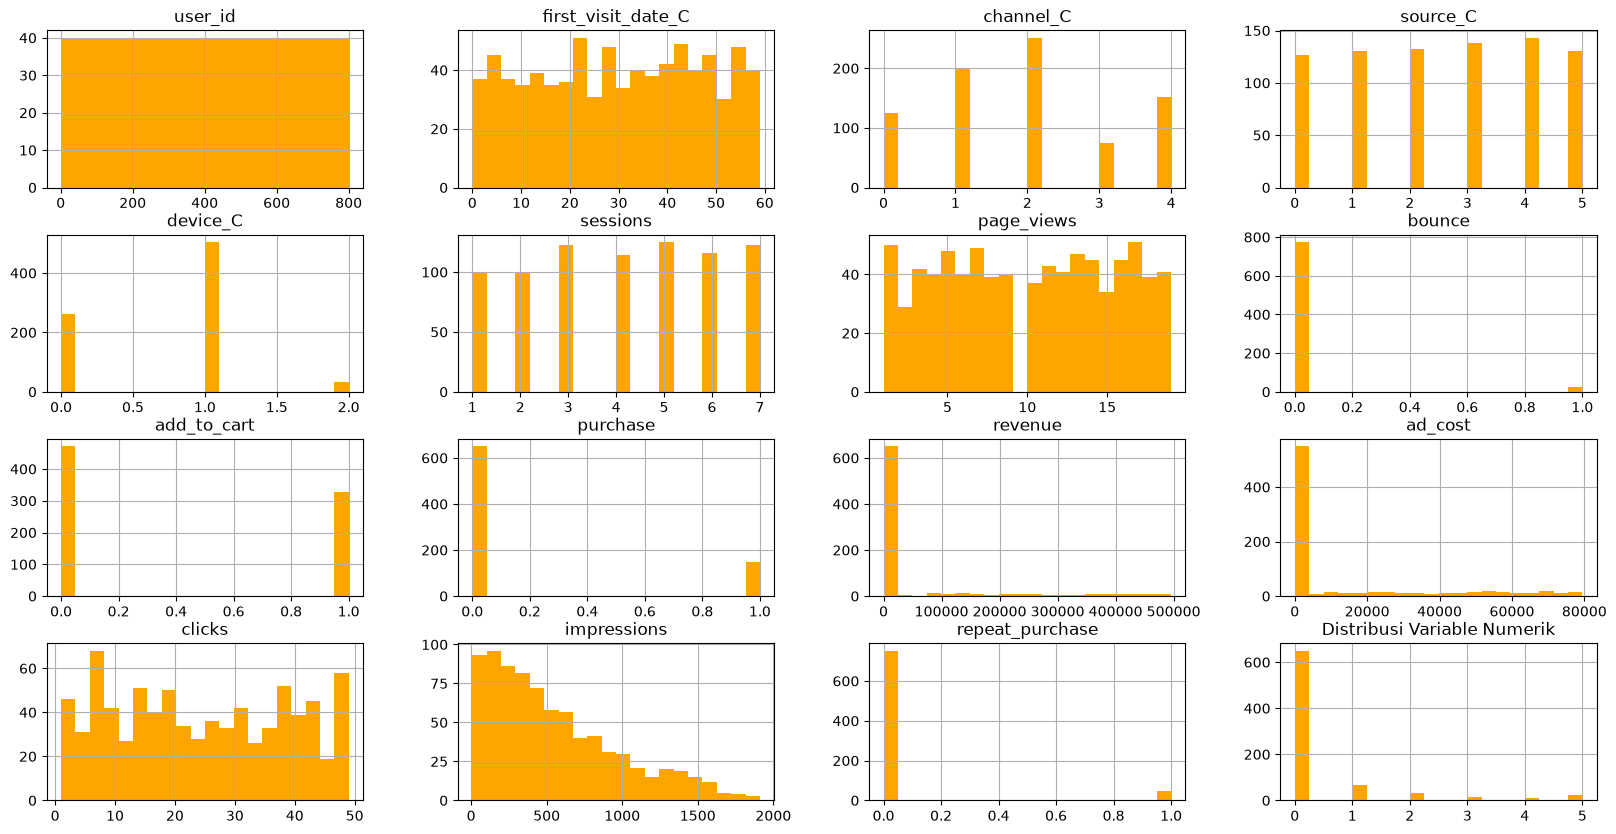

In [39]:
kolom_pilihan = ["user_id", 
                 "first_visit_date_C", 
                 "channel_C",
                 "source_C",
                 "device_C", 
                 "sessions", 
                 "page_views",
                 "bounce",
                 "add_to_cart",
                 "purchase",
                 "revenue",
                 "ad_cost",
                 "clicks",
                 "impressions",
                 "repeat_purchase",
                 "retention_month"
                ]
plt.figure(figsize=(12,8))
df_copy[kolom_pilihan].hist(bins = 20, figsize = (20,10), color = "orange")
plt.title("Distribusi Variable Numerik")
plt.show()

### Bivariat

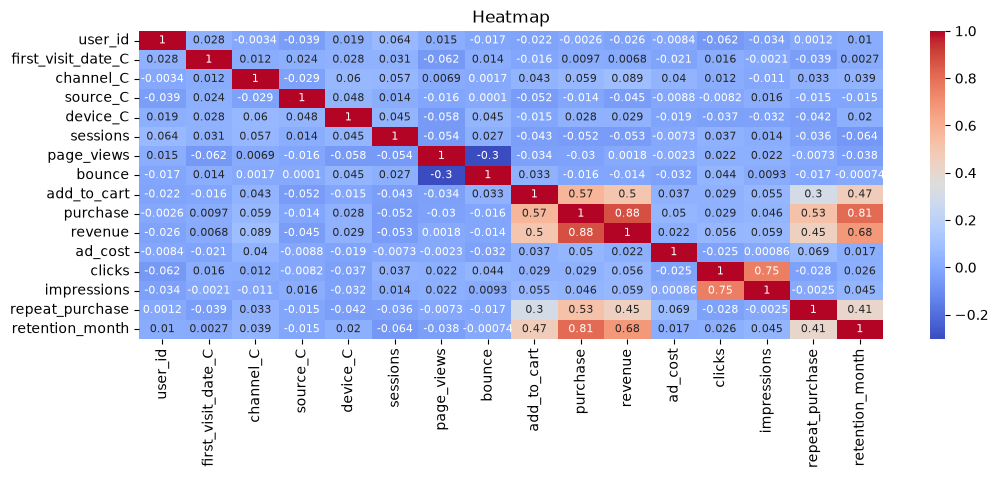

In [40]:
corr = df_copy[["user_id", 
                "first_visit_date_C", 
                "channel_C",
                "source_C",
                "device_C", 
                "sessions", 
                "page_views",
                "bounce",
                "add_to_cart",
                "purchase",
                "revenue",
                "ad_cost",
                "clicks",
                "impressions",
                "repeat_purchase",
                "retention_month"
               ]].corr()
plt.figure(figsize=(12, 4)) 
sns.heatmap(corr, annot=True, cmap="coolwarm", annot_kws={"size": 8})
plt.title("Heatmap")
plt.show()

### Multivariat

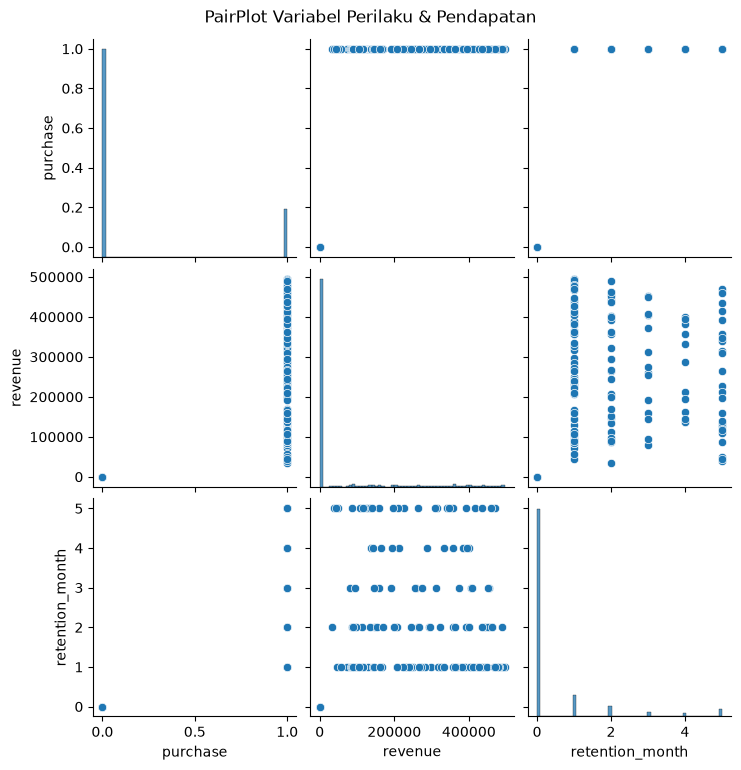

In [41]:
# Pilih subset kolom yang relevan
kolom_pilihan = ["channel", "purchase", "revenue", "retention_month"]

# Buat PairPlot
sns.pairplot(df_copy[kolom_pilihan])
plt.suptitle("PairPlot Variabel Perilaku & Pendapatan", y=1.02)
plt.show()

### Scatterplot

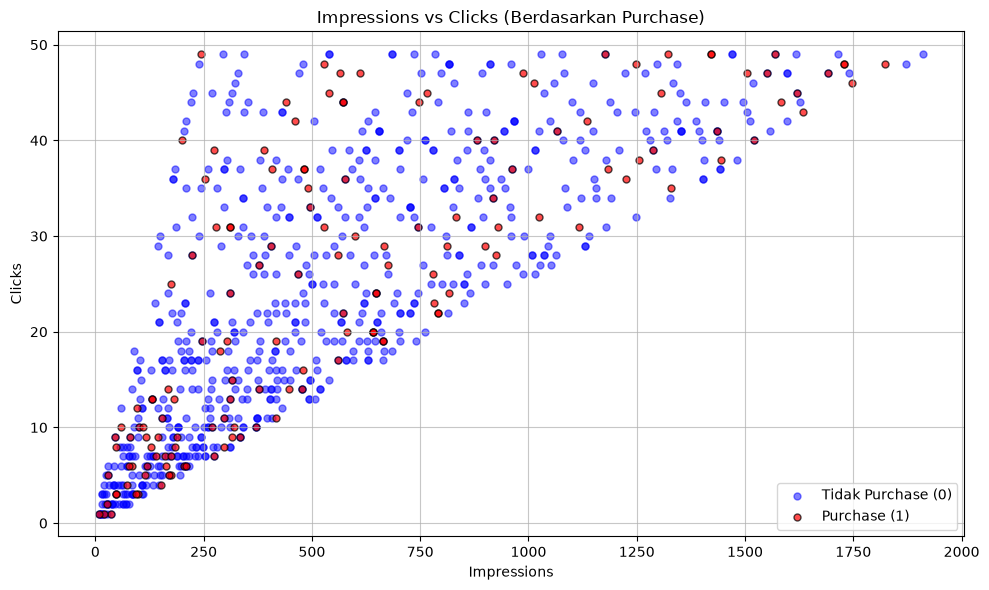

In [42]:
# Buat scatter plot
plt.figure(figsize=(10, 6))

# Pisahkan berdasarkan purchase
purchase_0 = df[df['purchase'] == 0]
purchase_1 = df[df['purchase'] == 1]

plt.scatter(purchase_0['impressions'], purchase_0['clicks'],
            c='blue', alpha=0.5, label='Tidak Purchase (0)', s=25)
plt.scatter(purchase_1['impressions'], purchase_1['clicks'],
            c='red', alpha=0.7, label='Purchase (1)', s=25, edgecolors='black')

plt.title('Impressions vs Clicks (Berdasarkan Purchase)')
plt.xlabel('Impressions')
plt.ylabel('Clicks')
plt.legend()
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()


# Kesimpulannya

Data data_marketing_growth_analytics ini tidak memiliki Missing value, Duplikasi dan tidak ada data yang typo, namu ada data yang Outlier. solusi untuk mengatasai Outlier adalah dengan mempertahankannya.